In [5]:

import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, minimize
from scipy.stats import norm, skew, spearmanr, qmc
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------- 
# Figures settings
# ---------------------------------------------------------------- 
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

SEED = 42
print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [ ]:
# ---------------------------------------------------------------- 
# Load data
# ---------------------------------------------------------------- 
X = np.load('..\Function_3_Data\Week_12_Data/F3_Week_12_inputs.npy')
y = np.load('..\Function_3_Data\Week_12_Data/F3_Week_12_outputs.npy')
n, d = X.shape
N_INITIAL = 15
NEW = n - 1
best = int(np.argmax(y))
x_best = X[best]
print(f"n = {n} ({N_INITIAL} initial + {n - N_INITIAL} queried); newest x = {np.round(X[NEW], 6)}, y = {y[NEW]:.6f}")
print(f"best observed: row {best}, x = {np.round(x_best, 6)}, y = {y[best]:.6f}")
print(f"newest ranks {int((y > y[NEW]).sum()) + 1} of {n} by y")


n = 26 (15 initial + 11 queried); newest x = [0.452356 0.609733 0.41828 ], y = -0.006465
best observed: row 24, x = [0.44653  0.572743 0.423725], y = -0.002265
newest ranks 2 of 26 by y


Target Transformations (skew; gap between best and second-best value in std units)
  log   skew +0.50   gap 0.89
  sqrt  skew -0.88   gap 0.26
  raw   skew -2.65   gap 0.05


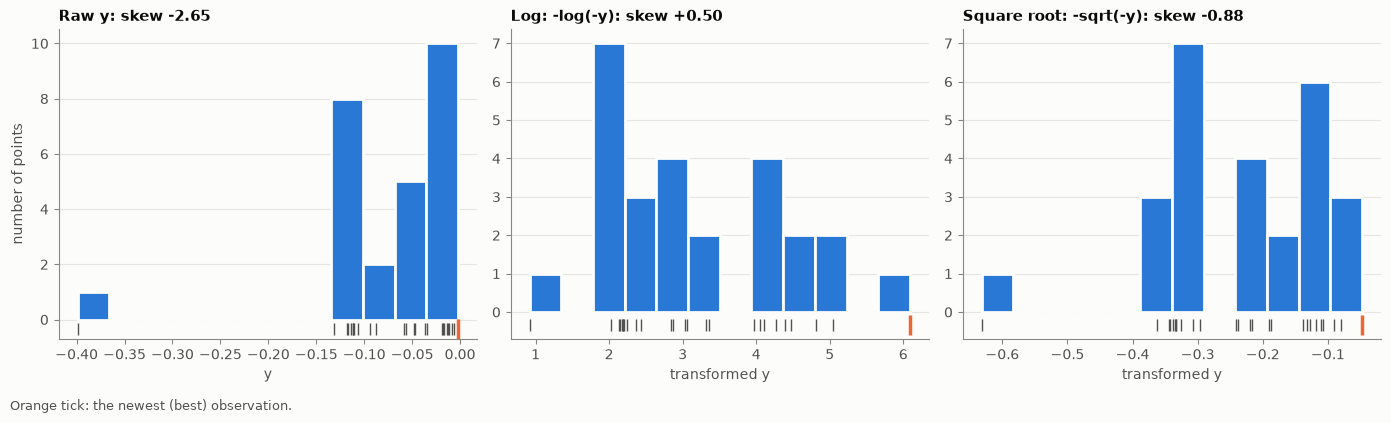

In [3]:
# ---------------------------------------------------------------- 
# Target transforms
# ---------------------------------------------------------------- 
TRANSFORMS = {
    "log": (lambda v: -np.log(-v), lambda m: -np.exp(-m)),
    "sqrt": (lambda v: -np.sqrt(-v), lambda m: -np.maximum(-m, 0) ** 2),
    "raw": (lambda v: v.copy(), lambda m: m),
}
print("=" * 100)
print("Target Transformations (skew; gap between best and second-best value in std units)")
print("=" * 100)
for name, (f, _) in TRANSFORMS.items():
    t = f(y)
    s = np.sort(t)
    print(f"  {name:5s} skew {skew(t):+.2f}   gap {(s[-1] - s[-2]) / t.std():.2f}")


# Fig 1: transforms
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (title, tname) in zip(axes, [("Raw y", "raw"), ("Log: -log(-y)", "log"), ("Square root: -sqrt(-y)", "sqrt")]):
    t = TRANSFORMS[tname][0](y)
    ax.hist(t, bins=12, color=BLUE, edgecolor=SURFACE, linewidth=2)
    ax.plot(t, np.full(n, -0.35), "|", color=INK2, markersize=9, clip_on=False)
    ax.plot(t[best], -0.35, "|", color=ORANGE, markersize=14, markeredgewidth=2.5, clip_on=False)
    ax.set_title(f"{title}: skew {skew(t):+.2f}"); ax.set_ylim(bottom=-0.7); ax.grid(axis="x", visible=False)
    ax.set_xlabel("transformed y" if tname != "raw" else "y")
axes[0].set_ylabel("number of points")
fig.text(0.01, 0.01, "Orange tick: the newest (best) observation.", color=INK2, fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))

MODELS (LOO with hyperparameters fixed at the full fit)
  log-iso   ls=[0.08]  LOO RMSE/std=0.728  Spearman=0.556  raw-y RMSE on top 9=0.0045  LOO pred at best row=-0.0100  noise (normalised var)=0.178
  log-ARD   ls=[1.00e+02 6.62e-01 9.50e-02]  LOO RMSE/std=0.558  Spearman=0.814  raw-y RMSE on top 9=0.0049  LOO pred at best row=-0.0115  noise (normalised var)=0.155
  sqrt-iso  ls=[0.163]  LOO RMSE/std=0.800  Spearman=0.690  raw-y RMSE on top 9=0.0056  LOO pred at best row=-0.0093  noise (normalised var)=0.026
  sqrt-ARD  ls=[100.      1.482   0.116]  LOO RMSE/std=0.752  Spearman=0.796  raw-y RMSE on top 9=0.0043  LOO pred at best row=-0.0105  noise (normalised var)=0.025
  raw-iso   ls=[0.255]  LOO RMSE/std=0.909  Spearman=0.763  raw-y RMSE on top 9=0.0048  LOO pred at best row=-0.0082  noise (normalised var)=0.001
  raw-ARD   ls=[100.      2.03    0.164]  LOO RMSE/std=1.075  Spearman=0.665  raw-y RMSE on top 9=0.0052  LOO pred at best row=-0.0100  noise (normalised var)=0.002




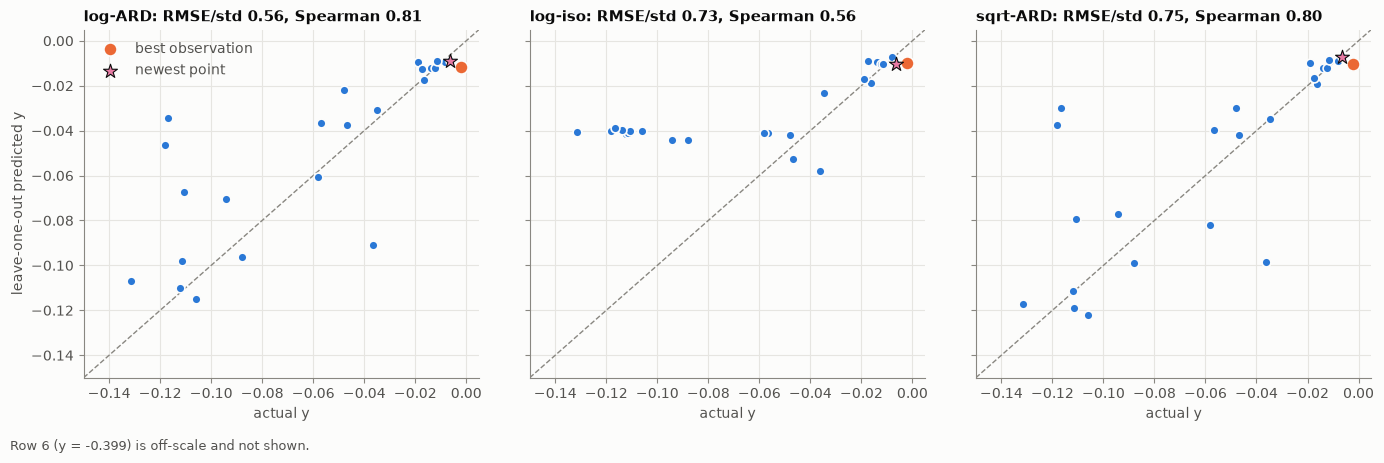

In [6]:
# ---------------------------------------------------------------- 
# GP models + LOO
# ---------------------------------------------------------------- 
def fit(Xf, t, ard):
    k = (ConstantKernel(1.0, (1e-2, 1e2)) * Matern(length_scale=np.ones(d) if ard else 1.0,
                                      length_scale_bounds=(1e-2, 1e2), nu=2.5)
         + WhiteKernel(1e-2, (1e-8, 3e-1)))
    return GaussianProcessRegressor(kernel=k, normalize_y=True, n_restarts_optimizer=20,
                                    random_state=SEED).fit(Xf, t)

top = np.argsort(-y)[:9]
models, loos = {}, {}
print('='*100)
print("MODELS (LOO with hyperparameters fixed at the full fit)")
print('='*100)
for tname, (f, back) in TRANSFORMS.items():
    t = f(y)
    for ard in (False, True):
        key = f"{tname}-{'ARD' if ard else 'iso'}"
        gp = fit(X, t, ard)
        mu = np.empty(n)
        for i in range(n):
            keep = np.arange(n) != i
            g = GaussianProcessRegressor(kernel=gp.kernel_, optimizer=None, normalize_y=True).fit(X[keep], t[keep])
            mu[i] = g.predict(X[i:i + 1])[0]
        models[key], loos[key] = gp, mu
        yb = back(mu)
        ls = np.atleast_1d(gp.kernel_.k1.k2.length_scale)
        print(f"  {key:9s} ls={np.round(ls, 3)}  LOO RMSE/std={np.sqrt(np.mean((t - mu) ** 2)) / t.std():.3f}  "
              f"Spearman={spearmanr(t, mu)[0]:.3f}  raw-y RMSE on top 9={np.sqrt(np.mean((y[top] - yb[top]) ** 2)):.4f}  "
              f"LOO pred at best row={yb[best]:.4f}  noise (normalised var)={gp.kernel_.k2.noise_level:.3f}")
        
print('\n')
# Fig 3: LOO in raw y for three models
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
for ax, key in zip(axes, ["log-ARD", "log-iso", "sqrt-ARD"]):
    yb = TRANSFORMS[key.split('-')[0]][1](loos[key])
    t = TRANSFORMS[key.split('-')[0]][0](y)
    keep = np.arange(n) != 6
    lim = [-0.15, 0.005]
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.scatter(y[keep], yb[keep], s=40, color=BLUE, edgecolor=SURFACE, linewidth=1.2, zorder=3)
    ax.scatter(y[best], yb[best], s=90, color=ORANGE, edgecolor=SURFACE, linewidth=1.2, zorder=4, label="best observation")
    ax.scatter(y[NEW], yb[NEW], s=110, marker="*", color=MAGENTA, edgecolor=INK, linewidth=0.8, zorder=4, label="newest point")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f"{key}: RMSE/std {np.sqrt(np.mean((t - loos[key]) ** 2)) / t.std():.2f}, "
                 f"Spearman {spearmanr(t, loos[key])[0]:.2f}")
    ax.set_xlabel("actual y")
axes[0].set_ylabel("leave-one-out predicted y")
axes[0].legend(frameon=False, loc="upper left", labelcolor=INK2)
fig.text(0.01, 0.01, "Row 6 (y = -0.399) is off-scale and not shown.", color=INK2, fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))

WEEK-11 PREDICTIONS at [0.452356 0.609733 0.41828 ] (models refitted on the first 25 rows); observed -0.006465
  log-ARD   predicted -0.00916   error +0.00270   z (transformed, incl. noise) +0.65
  log-iso   predicted -0.01062   error +0.00416   z (transformed, incl. noise) +0.71
  sqrt-ARD  predicted -0.00719   error +0.00073   z (transformed, incl. noise) +0.18
  sqrt-iso  predicted -0.01036   error +0.00390   z (transformed, incl. noise) +0.62
  raw-iso   predicted -0.00975   error +0.00329   z (transformed, incl. noise) +0.39
  raw-ARD   predicted -0.00333   error -0.00313   z (transformed, incl. noise) -0.73



WEEK-11 BOWL (9 points): centre [0.4582 0.6467 0.4128], curvatures [3.99 0.89 5.38]; predicted -0.00154 at the newest point (observed -0.00646)


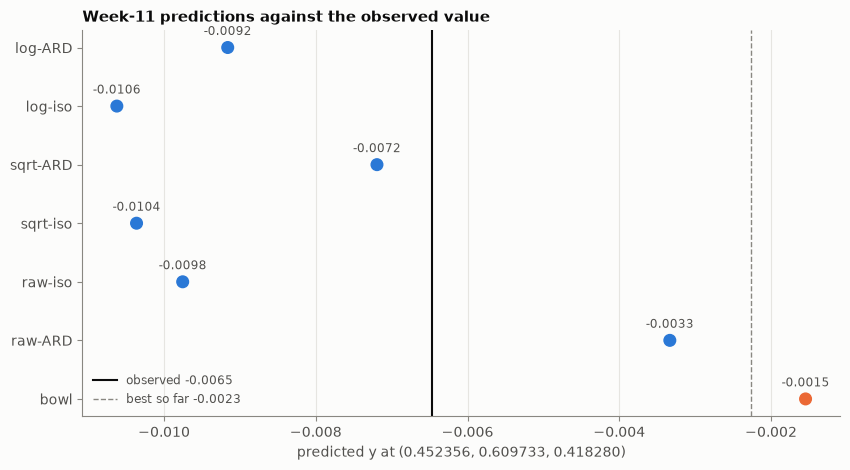

In [8]:
# ---------------------------------------------------------------- 
# Week-11 predictions at the newest point
# ---------------------------------------------------------------- 

PRED_KEYS = ["log-ARD", "log-iso", "sqrt-ARD", "sqrt-iso", "raw-iso", "raw-ARD"]
prev_pred = {}
print('='*100)
print(f"WEEK-11 PREDICTIONS at {np.round(X[NEW], 6)} (models refitted on the first {NEW} rows); observed {y[NEW]:.6f}")
print('='*100)

for key in PRED_KEYS:
    tname, kind = key.split("-")
    f, back = TRANSFORMS[tname]
    g = fit(X[:NEW], f(y[:NEW]), kind == "ARD")
    m, s = g.predict(X[NEW:NEW + 1], return_std=True)
    z = (f(y[NEW:NEW + 1])[0] - m[0]) / s[0]
    prev_pred[key] = back(m)[0]
    print(f"  {key:9s} predicted {back(m)[0]:+.5f}   error {y[NEW] - back(m)[0]:+.5f}   z (transformed, incl. noise) {z:+.2f}")
print('\n')


# ---------------------------------------------------------------- 
# Local bowl model
# -y = e + b1 (x1-c1)^2 + b2 (x2-c2)^2 + b3 (x3-c3)^2 on the cluster of best points
#-----------------------------------------------------------------

CL_OLD = [3, 16, 17, 18, 20, 21, 22, 23, 24]
CL = CL_OLD + [NEW]
LB, UB = [0, 0, 0, 0, 0, 0, 0], [1, 1e4, 1e4, 1e4, 1, 1, 1]
def bowl_res(p, Z, v):
    e, b1, b2, b3, c1, c2, c3 = p
    return e + b1 * (Z[:, 0] - c1) ** 2 + b2 * (Z[:, 1] - c2) ** 2 + b3 * (Z[:, 2] - c3) ** 2 - v

def fit_bowl(rows):
    p = least_squares(bowl_res, [0.002, 1, 1, 1, 0.45, 0.57, 0.42], args=(X[rows], -y[rows]), bounds=(LB, UB)).x
    jk = np.array([least_squares(bowl_res, p, args=(X[[j for j in rows if j != i]], -y[[j for j in rows if j != i]]),
                                 bounds=(LB, UB)).x[4:] for i in rows])
    return p, jk

def make_bowl(p):
    def f(Z):
        e, b1, b2, b3, c1, c2, c3 = p
        return -(e + b1 * (Z[:, 0] - c1) ** 2 + b2 * (Z[:, 1] - c2) ** 2 + b3 * (Z[:, 2] - c3) ** 2)
    return f

p_old, _ = fit_bowl(CL_OLD)
bowl_old = make_bowl(p_old)
p_bowl, jack = fit_bowl(CL)
bowl = make_bowl(p_bowl)
centre = p_bowl[4:]
print(f"\nWEEK-11 BOWL (9 points): centre {np.round(p_old[4:], 4)}, curvatures {np.round(p_old[1:4], 2)}; "
      f"predicted {bowl_old(X[NEW:NEW + 1])[0]:+.5f} at the newest point (observed {y[NEW]:+.5f})")

# Fig 2: week-11 predictions vs outcome
fig, ax = plt.subplots(figsize=(8.6, 4.8))
names = PRED_KEYS + ["bowl"]
vals = [prev_pred[k] for k in PRED_KEYS] + [bowl_old(X[NEW:NEW + 1])[0]]
cols = [BLUE] * len(PRED_KEYS) + [ORANGE]
ypos = np.arange(len(names))[::-1]
ax.scatter(vals, ypos, s=70, color=cols, zorder=3)
ax.axvline(y[NEW], color=INK, lw=1.5, label=f"observed {y[NEW]:.4f}")
ax.axvline(y[best], color=MUTED, lw=1, ls="--", label=f"best so far {y[best]:.4f}")
for v_, p_ in zip(vals, ypos):
    ax.annotate(f"{v_:.4f}", (v_, p_), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8.5, color=INK2)
ax.set_yticks(ypos); ax.set_yticklabels(names)
ax.set_xlabel("predicted y at (0.452356, 0.609733, 0.418280)")
ax.set_title("Week-11 predictions against the observed value")
ax.legend(frameon=False, loc="lower left", fontsize=8.5, labelcolor=INK2)
ax.grid(axis="y", visible=False)
fig.tight_layout()

BOWL MODEL on rows [3, 16, 17, 18, 20, 21, 22, 23, 24, 25]:
Floor e = 0.005297, curvatures b = [3.99 1.7  4.38], centre = [0.456939 0.591514 0.413642]
Residuals (bowl - y): [ 0.0001 -0.0017  0.0009 -0.0004  0.002   0.0014  0.0003  0.0015 -0.0045
  0.0004] rms 0.0018
Leave-one-out centres: min [0.33  0.578 0.406], max [0.473 0.647 0.418]
Bowl at best point -0.00677 (observed -0.00226); bowl at centre -0.00530




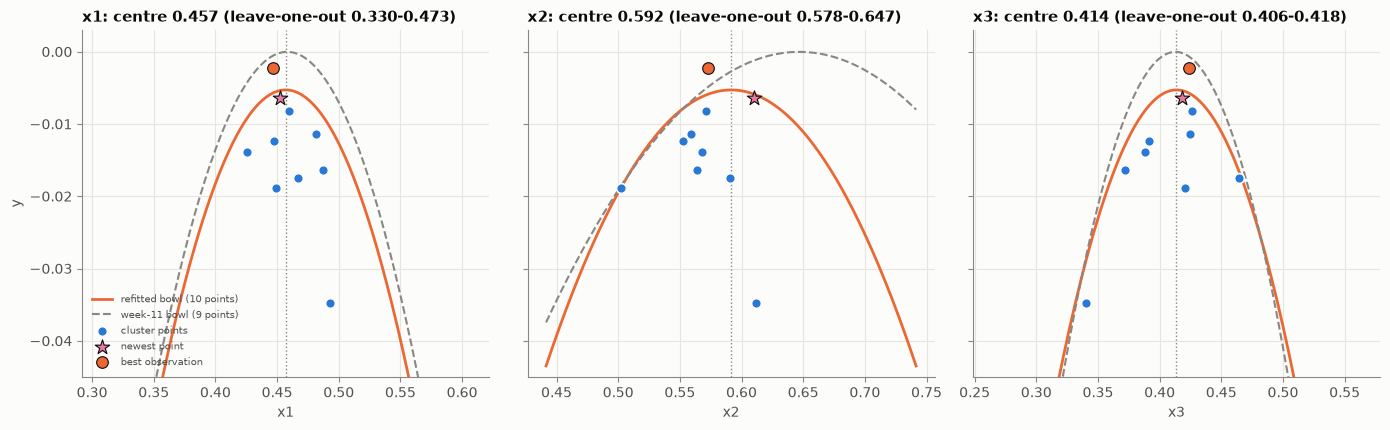

In [11]:
print('='*100)
print(f"BOWL MODEL on rows {CL}:\nFloor e = {p_bowl[0]:.6f}, curvatures b = {np.round(p_bowl[1:4], 2)}, "f"centre = {np.round(centre, 6)}")
print(f"Residuals (bowl - y): {np.round(bowl(X[CL]) - y[CL], 4)} rms {np.sqrt(np.mean((bowl(X[CL]) - y[CL]) ** 2)):.4f}")
print(f"Leave-one-out centres: min {np.round(jack.min(0), 3)}, max {np.round(jack.max(0), 3)}")
print(f"Bowl at best point {bowl(x_best[None])[0]:+.5f} (observed {y[best]:+.5f}); "f"bowl at centre {bowl(centre[None])[0]:+.5f}")
print('='*100)
print('\n')

# Fig 4: cluster points vs each input, with the refitted bowl (and last week's) through its centre
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)
for j, ax in enumerate(axes):
    xs = np.linspace(centre[j] - 0.15, centre[j] + 0.15, 200)
    Z = np.tile(centre, (len(xs), 1)); Z[:, j] = xs
    ax.plot(xs, bowl(Z), color=ORANGE, lw=2, label="refitted bowl (10 points)")
    Z2 = np.tile(p_old[4:], (len(xs), 1)); Z2[:, j] = xs
    ax.plot(xs, bowl_old(Z2), color=MUTED, lw=1.5, ls="--", label="week-11 bowl (9 points)")
    ax.scatter(X[CL_OLD, j], y[CL_OLD], s=50, color=BLUE, edgecolor=SURFACE, linewidth=1.2, zorder=3, label="cluster points")
    ax.scatter(X[NEW, j], y[NEW], s=120, marker="*", color=MAGENTA, edgecolor=INK, linewidth=0.8, zorder=4, label="newest point")
    ax.scatter(x_best[j], y[best], s=70, color=ORANGE, edgecolor=INK, linewidth=0.8, zorder=4, label="best observation")
    ax.axvline(centre[j], color=MUTED, lw=1, ls=":")
    ax.set_xlabel(f"x{j + 1}"); ax.set_ylim(-0.045, 0.003)
    ax.set_title(f"x{j + 1}: centre {centre[j]:.3f} (leave-one-out {jack[:, j].min():.3f}-{jack[:, j].max():.3f})")
axes[0].set_ylabel("y")
axes[0].legend(frameon=False, loc="lower left", fontsize=7.5, labelcolor=INK2)
fig.tight_layout()

CANDIDATES: predicted y under each model
Reference at best point: log-ARD=-0.0090  log-iso=-0.0068  sqrt-ARD=-0.0085  raw-iso=-0.0048  bowl=-0.0068
  A: EI, log-ARD (xi = 0.02)               x = (0.347333, 0.817558, 0.422687)  dist 0.264  log-ARD=-0.0076  log-iso=-0.0427  sqrt-ARD=-0.0019  raw-iso=-0.0656  bowl=-0.1403  | mean gain vs best (4 GPs) -0.0222
  B: EI, log-isotropic (xi = 0.02)         x = (0.438558, 0.582029, 0.425653)  dist 0.012  log-ARD=-0.0089  log-iso=-0.0066  sqrt-ARD=-0.0083  raw-iso=-0.0038  bowl=-0.0074  | mean gain vs best (4 GPs) +0.0004
  C: refitted bowl centre                  x = (0.456939, 0.591514, 0.413642)  dist 0.024  log-ARD=-0.0088  log-iso=-0.0074  sqrt-ARD=-0.0077  raw-iso=-0.0059  bowl=-0.0053  | mean gain vs best (4 GPs) -0.0002
  D: ensemble-mean maximum (+/-0.06 box)   x = (0.435708, 0.592440, 0.422576)  dist 0.023  log-ARD=-0.0086  log-iso=-0.0069  sqrt-ARD=-0.0076  raw-iso=-0.0037  bowl=-0.0074  | mean gain vs best (4 GPs) +0.0005
  E: midpoin

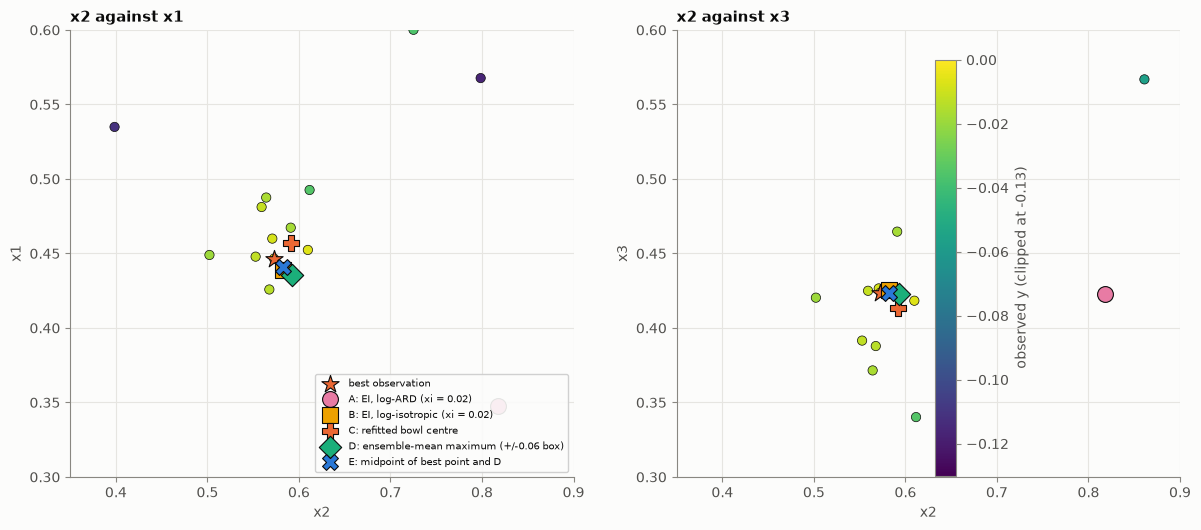

In [15]:
# ---------------------------------------------------------------- 
# Candidates
#-----------------------------------------------------------------

S = qmc.Sobol(d, seed=1).random(2 ** 14)

def gp_pred(key, Z):
    tname = key.split("-")[0]
    return TRANSFORMS[tname][1](models[key].predict(Z))

def ei_t(key, Z, xi):
    """EI in the model's transformed (normalised) target space."""
    tname = key.split("-")[0]
    f = TRANSFORMS[tname][0]
    gp = models[key]
    mu, s = gp.predict(Z, return_std=True)
    mu_tr = gp.predict(X)
    fbest = mu_tr.max()
    s = np.maximum(s, 1e-12)

    sc = f(y).std()
    z = (mu - fbest - xi * sc) / s
    return (mu - fbest - xi * sc) * norm.cdf(z) + s * norm.pdf(z)

def argmax_in(fn, lo, hi):
    Z = lo + S * (hi - lo)
    x0 = Z[fn(Z).argmax()]
    r = minimize(lambda q: -fn(q[None])[0], x0, bounds=list(zip(lo, hi)), method="L-BFGS-B")
    return r.x

full_lo, full_hi = np.zeros(d), np.ones(d)
BOX = 0.06
box_lo, box_hi = np.clip(x_best - BOX, 0, 1), np.clip(x_best + BOX, 0, 1)
ENS = ["log-ARD", "log-iso", "sqrt-ARD", "raw-iso"]
ens_rel = lambda Z: np.mean([gp_pred(k, Z) - gp_pred(k, x_best[None])[0] for k in ENS], axis=0)

x_ei_ard = argmax_in(lambda Z: ei_t("log-ARD", Z, 0.02), full_lo, full_hi)
x_ei_iso = argmax_in(lambda Z: ei_t("log-iso", Z, 0.02), full_lo, full_hi)
x_ens = argmax_in(ens_rel, box_lo, box_hi)
cands = {
    "A: EI, log-ARD (xi = 0.02)": x_ei_ard,
    "B: EI, log-isotropic (xi = 0.02)": x_ei_iso,
    "C: refitted bowl centre": centre,
    "D: ensemble-mean maximum (+/-0.06 box)": x_ens,
    "E: midpoint of best point and D": 0.5 * (x_best + x_ens),
}
KEYS = ["log-ARD", "log-iso", "sqrt-ARD", "raw-iso"]
print('='*100)
print("CANDIDATES: predicted y under each model")
ref = {k: gp_pred(k, x_best[None])[0] for k in KEYS} 
ref["bowl"] = bowl(x_best[None])[0]
print("Reference at best point: " + "  ".join(f"{k}={v:.4f}" for k, v in ref.items()))
print('='*100)
cand_pred = {}
for name, xc in cands.items():
    preds = {k: gp_pred(k, xc[None])[0] for k in KEYS}
    preds["bowl"] = bowl(xc[None])[0]
    cand_pred[name] = preds
    ens = np.mean([preds[k] - ref[k] for k in ENS])
    print(f"  {name:40s} x = ({xc[0]:.6f}, {xc[1]:.6f}, {xc[2]:.6f})  dist {np.linalg.norm(xc - x_best):.3f}  "
          + "  ".join(f"{k}={v:.4f}" for k, v in preds.items()) + f"  | mean gain vs best (4 GPs) {ens:+.4f}")

print('\n')

# Fig 5: candidates in two projections
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
marks = [("o", MAGENTA), ("s", YELLOW), ("P", ORANGE), ("D", AQUA), ("X", BLUE)]
for ax, (i, j) in zip(axes, [(1, 0), (1, 2)]):
    sc = ax.scatter(X[:, i], X[:, j], c=y, cmap="viridis", vmin=-0.13, vmax=0, s=45, edgecolor=INK, linewidth=0.5, zorder=3)
    ax.scatter(X[best, i], X[best, j], s=170, marker="*", color=ORANGE, edgecolor=INK, linewidth=0.8, zorder=4, label="best observation")
    for (name, xc), (m_, c_) in zip(cands.items(), marks):
        ax.scatter(xc[i], xc[j], s=130, marker=m_, color=c_, edgecolor=INK, linewidth=0.8, zorder=5, label=name)
    ax.set_xlabel(f"x{i + 1}"); ax.set_ylabel(f"x{j + 1}")
    ax.set_xlim(0.35, 0.9); ax.set_ylim(0.3, 0.6)
axes[0].set_title("x2 against x1"); axes[1].set_title("x2 against x3")
fig.colorbar(sc, ax=axes, label="observed y (clipped at -0.13)")
axes[0].legend(frameon=True, fontsize=7.5, loc="lower right", framealpha=0.9)
fig.tight_layout()

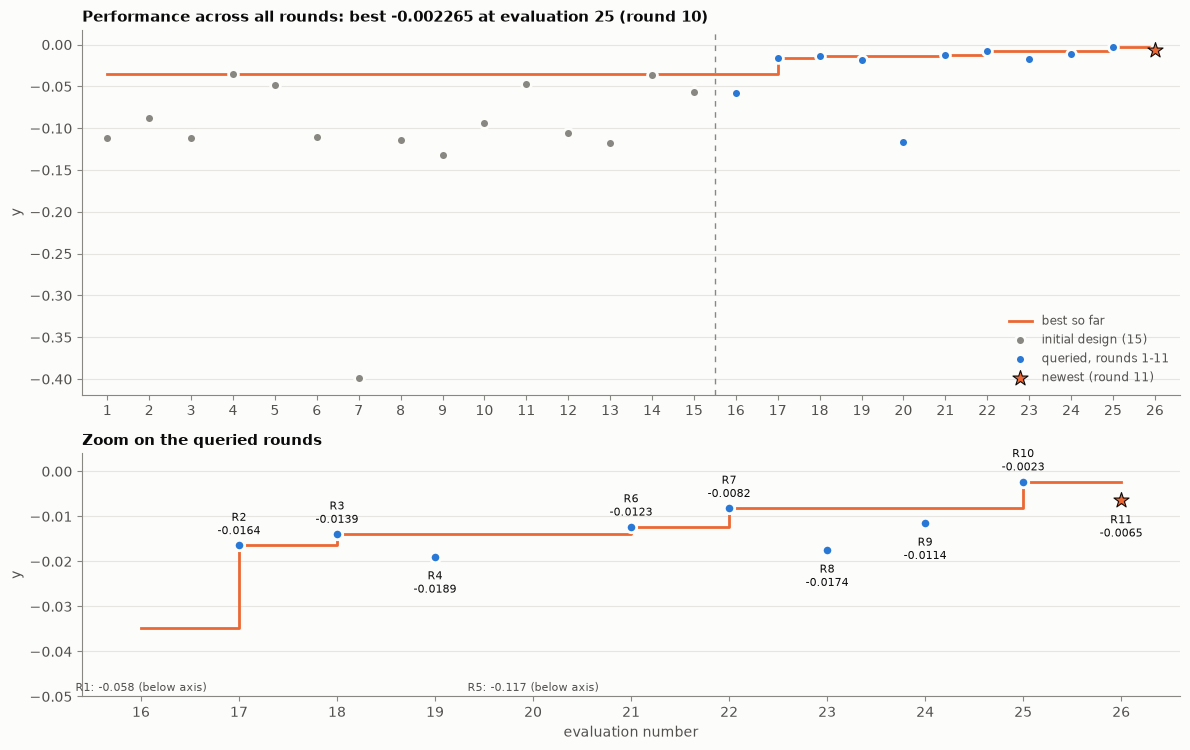

In [16]:
# Fig 1: performance across all rounds
idx = np.arange(1, n + 1)
bsf = np.maximum.accumulate(np.r_[np.full(N_INITIAL, y[:N_INITIAL].max()), y[N_INITIAL:]])
fig, (ax, az) = plt.subplots(2, 1, figsize=(12, 7.6), height_ratios=[3, 2])
ax.axvline(N_INITIAL + 0.5, color=MUTED, lw=1, ls=(0, (4, 4)))
ax.step(idx, bsf, where="post", color=ORANGE, lw=2, label="best so far", zorder=2)
ax.scatter(idx[:N_INITIAL], y[:N_INITIAL], s=50, color=MUTED, edgecolor=SURFACE, linewidth=2,
           label=f"initial design ({N_INITIAL})", zorder=3)
ax.scatter(idx[N_INITIAL:], y[N_INITIAL:], s=50, color=BLUE, edgecolor=SURFACE, linewidth=2,
           label=f"queried, rounds 1-{n - N_INITIAL}", zorder=3)
ax.scatter(idx[NEW], y[NEW], s=130, marker="*", color=ORANGE, edgecolor=INK, linewidth=0.8, zorder=4,
           label="newest (round 11)")
ax.set_xticks(idx); ax.set_xlim(0.4, n + 0.6); ax.grid(axis="x", visible=False); ax.set_ylabel("y")
ax.set_title(f"Performance across all rounds: best {y.max():.6f} at evaluation {best + 1} (round {best - N_INITIAL + 1})")
ax.legend(frameon=False, loc="lower right", fontsize=8.5, labelcolor=INK2)
q = np.arange(N_INITIAL, n)
az.step(idx[q], bsf[q], where="post", color=ORANGE, lw=2, zorder=2)
az.scatter(idx[q], y[q], s=56, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
az.scatter(idx[NEW], y[NEW], s=130, marker="*", color=ORANGE, edgecolor=INK, linewidth=0.8, zorder=4)
for i in q:
    if y[i] > -0.05:
        az.annotate(f"R{i - N_INITIAL + 1}\n{y[i]:.4f}", (idx[i], y[i]), xytext=(0, 8 if y[i] >= bsf[i] - 1e-12 else -26),
                    textcoords="offset points", ha="center", fontsize=8, color=INK)
    else:
        az.annotate(f"R{i - N_INITIAL + 1}: {y[i]:.3f} (below axis)", (idx[i], -0.05), xytext=(0, 4),
                    textcoords="offset points", ha="center", fontsize=8, color=INK2)
az.set_ylim(-0.05, 0.004); az.set_xticks(idx[q]); az.set_xlim(N_INITIAL + 0.4, n + 0.6)
az.grid(axis="x", visible=False); az.set_xlabel("evaluation number"); az.set_ylabel("y")
az.set_title("Zoom on the queried rounds")
fig.tight_layout(); 
